# TD – House Prices Regression
**Authors:** Malak Rai & Ayoub Outahar

In [1]:
%reset

Once deleted, variables cannot be recovered. Proceed (y/[n])?  y


In [2]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from torch import nn, optim
from torch.utils.data import DataLoader
import torch.nn.functional as F
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
%matplotlib inline


seed = 42
torch.manual_seed(seed)
np.random.seed(seed)
torch.cuda.manual_seed_all(seed)

In [3]:
'''read csv file qnd add r to convert to normal string'''

import pandas as pd
data_train = pd.read_csv("data/train_hp.csv")
X_test = pd.read_csv("data/test_hp.csv")
X_test.head()   #affiche les 5 premier lignes du fichier 

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1461,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,...,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
1,1462,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
2,1463,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal
3,1464,60,RL,78.0,9978,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,6,2010,WD,Normal
4,1465,120,RL,43.0,5005,Pave,NaN,IR1,HLS,AllPub,...,144,0,NaN,NaN,NaN,0,1,2010,WD,Normal


In [4]:
'''Use .head() or the variable to visualize the data from the .csv files. 
By using data_train.head() you can by default read 5 rows of data. You can also set data_train.head(10)'''

data_train.head(10)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
5,6,50,RL,85.0,14115,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,MnPrv,Shed,700,10,2009,WD,Normal,143000
6,7,20,RL,75.0,10084,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,307000
7,8,60,RL,NaN,10382,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,Shed,350,11,2009,WD,Normal,200000
8,9,50,RM,51.0,6120,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2008,WD,Abnorml,129900
9,10,190,RL,50.0,7420,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,1,2008,WD,Normal,118000


In [5]:
'''append the train (has las column as sale price and test does not have the sale prices) and test data 
 We do not want to carry the same indexing from the original data set thus we ignore idex and we do not want to sort the data.''' 

'''Use data_train.append() or pd.concat() based on your pandas version'''

# data = data_train.append(X_test, ignore_index=True, sort=False)
data = pd.concat([data_train,X_test],ignore_index=True,sort=False)# ce block sert a fusionner train data avec test data pour les manipuler de la meme facon
data.head(20)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500.0
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500.0
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500.0
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000.0
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000.0
5,6,50,RL,85.0,14115,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,MnPrv,Shed,700,10,2009,WD,Normal,143000.0
6,7,20,RL,75.0,10084,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,307000.0
7,8,60,RL,NaN,10382,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,Shed,350,11,2009,WD,Normal,200000.0
8,9,50,RM,51.0,6120,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2008,WD,Abnorml,129900.0
9,10,190,RL,50.0,7420,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,1,2008,WD,Normal,118000.0


In [6]:
''' Perform one hot encoding on all the categorical variables.
 Also, all the nan variables are also processed
 more infomration:  see the get dummies link  #https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.get_dummies.html
http://fastml.com/how-to-use-pd-dot-get-dummies-with-the-test-set/ '''
# One-hot encoding : chaque colonne texte est remplacée par une colonne booléenne (1/0) par valeur possible ; par ex. Street devient Street_Pave et Street_Grvl, avec 1 pour la valeur de la maison et 0 pour les autres. 
#dummy_na=True ajoute une colonne _nan pour garder l'info « valeur absente »
data = pd.get_dummies(data,dummy_na=True)
data.head()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,SaleType_Oth,SaleType_WD,SaleType_nan,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial,SaleCondition_nan
0,1,60,65.0,8450,7,5,2003,2003,196.0,706.0,...,False,True,False,False,False,False,False,True,False,False
1,2,20,80.0,9600,6,8,1976,1976,0.0,978.0,...,False,True,False,False,False,False,False,True,False,False
2,3,60,68.0,11250,7,5,2001,2002,162.0,486.0,...,False,True,False,False,False,False,False,True,False,False
3,4,70,60.0,9550,7,5,1915,1970,0.0,216.0,...,False,True,False,True,False,False,False,False,False,False
4,5,60,84.0,14260,8,5,2000,2000,350.0,655.0,...,False,True,False,False,False,False,False,True,False,False


In [7]:
#check if any vaue is missing! 
data.isnull().values.any()

#'''Will return True of False depending on the data. True if there is a missing value and false if there are no missing values'''

np.True_

In [8]:
'''Fill the missing data with the medain of the data in it's place. Use data.fillna() and data.median() functions'''
data.fillna(data.median(numeric_only=True), inplace=True)
# On utilise la médiane plutôt que la moyenne car elle n'est presque pas influencée par les valeurs extrêmes, donc elle remplace les cases vides par une valeur typique.

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,SaleType_Oth,SaleType_WD,SaleType_nan,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial,SaleCondition_nan
0,1,60,65.0,8450,7,5,2003,2003,196.0,706.0,...,False,True,False,False,False,False,False,True,False,False
1,2,20,80.0,9600,6,8,1976,1976,0.0,978.0,...,False,True,False,False,False,False,False,True,False,False
2,3,60,68.0,11250,7,5,2001,2002,162.0,486.0,...,False,True,False,False,False,False,False,True,False,False
3,4,70,60.0,9550,7,5,1915,1970,0.0,216.0,...,False,True,False,True,False,False,False,False,False,False
4,5,60,84.0,14260,8,5,2000,2000,350.0,655.0,...,False,True,False,False,False,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2914,2915,160,21.0,1936,4,7,1970,1970,0.0,0.0,...,False,True,False,False,False,False,False,True,False,False
2915,2916,160,21.0,1894,4,5,1970,1970,0.0,252.0,...,False,True,False,True,False,False,False,False,False,False
2916,2917,20,160.0,20000,5,7,1960,1996,0.0,1224.0,...,False,True,False,True,False,False,False,False,False,False
2917,2918,85,62.0,10441,5,5,1992,1992,0.0,337.0,...,False,True,False,False,False,False,False,True,False,False


In [9]:
# Recheck if there are any missing values

data.isnull().values.any() 

np.False_

In [10]:
''' The objective here is to estimate the sale price of the house given the features of the house'''

columns = data.columns
sale_price_orignal = data['SalePrice']
data.isnull().values.any() #pour verifier si il y a encore des valeurs Nan
sale_price_orignal.head()

0    208500.0
1    181500.0
2    223500.0
3    140000.0
4    250000.0
Name: SalePrice, dtype: float64

In [11]:
#normalization , standardization
#we use minmaxscaler to transform our values to be betwen 0 and 1 (0.2545.....)
scaler = MinMaxScaler()
data = pd.DataFrame(scaler.fit_transform(data), columns = columns)
data['SalePrice'] = sale_price_orignal
data.head()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,SaleType_Oth,SaleType_WD,SaleType_nan,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial,SaleCondition_nan
0,0.000000,0.235294,0.150685,0.033420,0.666667,0.500,0.949275,0.883333,0.12250,0.125089,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,0.000343,0.000000,0.202055,0.038795,0.555556,0.875,0.753623,0.433333,0.00000,0.173281,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,0.000685,0.235294,0.160959,0.046507,0.666667,0.500,0.934783,0.866667,0.10125,0.086109,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,0.001028,0.294118,0.133562,0.038561,0.666667,0.500,0.311594,0.333333,0.00000,0.038271,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.001371,0.235294,0.215753,0.060576,0.777778,0.500,0.927536,0.833333,0.21875,0.116052,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


In [12]:
#what does iloc do???  and what does MinMaxscaler do? 
# We merged the train and test data so they are encoded and scaled in the same way; now we split them back (using iloc) to train the model on the train data and make predictions on the test data. 

# we use minmaxscaler to transform our values to be betwen 0 and 1 (ex:0.2545.....)
# iloc selects rows or columns by position

In [27]:
train = data.iloc[:1460]
test = data.iloc[1460:]
test.drop('SalePrice', axis=1, inplace=True)# on enleve la cologne des prix des maisons de la test data
test.head()
train.head()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,SaleType_Oth,SaleType_WD,SaleType_nan,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial,SaleCondition_nan
0,0.000000,0.235294,0.150685,0.033420,0.666667,0.500,0.949275,0.883333,0.12250,0.125089,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,0.000343,0.000000,0.202055,0.038795,0.555556,0.875,0.753623,0.433333,0.00000,0.173281,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,0.000685,0.235294,0.160959,0.046507,0.666667,0.500,0.934783,0.866667,0.10125,0.086109,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,0.001028,0.294118,0.133562,0.038561,0.666667,0.500,0.311594,0.333333,0.00000,0.038271,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.001371,0.235294,0.215753,0.060576,0.777778,0.500,0.927536,0.833333,0.21875,0.116052,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


In [28]:
'''split test and train data into training data set and validation data set. Use the function train_test_split() '''

X_train, X_val = train_test_split(train, train_size=1000, random_state=42)  # tirage aléatoire mais fixé par la seed, pour avoir toujours la même validation et comparer les modèles de façon juste
y_val = X_val['SalePrice'].copy()

In [29]:
print(X_train.shape)
print(X_val.shape)

(1000, 332)
(460, 332)


In [30]:
'''create the NN network in a Regressor Class. Make sure the check the dimensions of input and output data'''
import torch.nn.functional as F
class Regressor(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden1 = nn.Linear(331, 128) # hidden layer 1 : 331 features -> 128 neurones
        self.hidden2 = nn.Linear(128, 64)          # hidden layer 2 : 128 -> 64 neurones
        self.output = nn.Linear(64, 1)
        


    def forward(self,x): 
        x = F.relu(self.hidden1(x))  # ReLU : keeps positive values, sets negatives to 0 ; learns faster than sigmoid
        x = F.relu(self.hidden2(x))
        x = self.output(x)

        return x

### The input size is 331 because each house is described by 331 features (332 columns minus SalePrice), and the output size is 1 because we predict a single value: the house price.
### We use 2 hidden layers (128 then 64 neurons) so the model can learn more complex relationships between the features and the price. We use ReLU instead of sigmoid because it learns faster and does not saturate.

In [31]:
'''set the training and test batch into 50 batches
You can use numpy.split to split along the first axis n times, where n is the number of desired batches.'''

train_batch = np.split(X_train.drop(columns=['SalePrice']), 50)
label_batch = np.split(np.log(X_train['SalePrice']), 50)    # We predict log(price) because it makes learning easier

In [32]:
# create the torch tensors for  train batch and  labels (y train values)
for i in range(len(train_batch)):
    train_batch[i] = torch.from_numpy(train_batch[i]).float()
for i in range(len(label_batch)):
    label_batch[i] = torch.from_numpy(label_batch[i]).float().view(-1, 1) # view is added so that sizes are respected
#it can be verified that now train test batches are tensors


In [33]:
train_batch[0].shape

torch.Size([20, 331])

In [34]:
label_batch[0].shape

torch.Size([20, 1])

In [35]:
'''prepare test or validation sets and convert them to tensors '''

#X_val = torch.from_numpy(X_val.values).float()
#y_val = torch.from_numpy(y_val.values).float().view(-1, 1)

y_val = torch.tensor(np.log(X_val['SalePrice'].to_numpy()), dtype=torch.float32).view(-1, 1)  # vrais prix en log, forme (460, 1)
X_val = torch.tensor(X_val.drop(columns=['SalePrice']).to_numpy(), dtype=torch.float32)  # features seulement, forme (460, 331)

print(X_val.shape)
print(y_val.shape)

torch.Size([460, 331])
torch.Size([460, 1])


In [36]:
#train the model
model = Regressor()
ps = model(train_batch[0])
ps.shape

torch.Size([20, 1])

### We train the model with MSE on log prices (the prices were already converted to log in the batches), so the error is relative to the price and large errors are penalized more. We display the RMSE (square root of the MSE) because it is in the same unit as the target. Adam adjusts the weights to reduce this loss. A learning rate of 0.0005 gives small updates, and 50 epochs lets the model pass through the training data 50 times.

In [46]:
model = Regressor()
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.0005)
epochs = 50
train_losses, val_losses = [], []

for e in range(epochs):
    model.train()
    train_loss = 0
    for i in range(len(train_batch)):
        optimizer.zero_grad()
        predictions = model(train_batch[i])
        loss = criterion(predictions, label_batch[i])
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    model.eval()
    with torch.no_grad():
        val_loss = criterion(model(X_val), y_val).item()

    train_losses.append(train_loss / len(train_batch))  
    val_losses.append(val_loss)
    print(f"Epoch {e+1}/{epochs} | Training loss: {train_loss/len(train_batch):.4f} | Validation loss: {val_loss:.4f}")

Epoch 1/50 | Training loss: 88.3061 | Validation loss: 2.5052
Epoch 2/50 | Training loss: 0.8741 | Validation loss: 0.0908
Epoch 3/50 | Training loss: 0.0905 | Validation loss: 0.0720
Epoch 4/50 | Training loss: 0.0662 | Validation loss: 0.0595
Epoch 5/50 | Training loss: 0.0529 | Validation loss: 0.0511
Epoch 6/50 | Training loss: 0.0443 | Validation loss: 0.0456
Epoch 7/50 | Training loss: 0.0385 | Validation loss: 0.0417
Epoch 8/50 | Training loss: 0.0342 | Validation loss: 0.0389
Epoch 9/50 | Training loss: 0.0309 | Validation loss: 0.0368
Epoch 10/50 | Training loss: 0.0282 | Validation loss: 0.0351
Epoch 11/50 | Training loss: 0.0260 | Validation loss: 0.0337
Epoch 12/50 | Training loss: 0.0241 | Validation loss: 0.0324
Epoch 13/50 | Training loss: 0.0224 | Validation loss: 0.0314
Epoch 14/50 | Training loss: 0.0209 | Validation loss: 0.0304
Epoch 15/50 | Training loss: 0.0196 | Validation loss: 0.0296
Epoch 16/50 | Training loss: 0.0185 | Validation loss: 0.0288
Epoch 17/50 | Tr

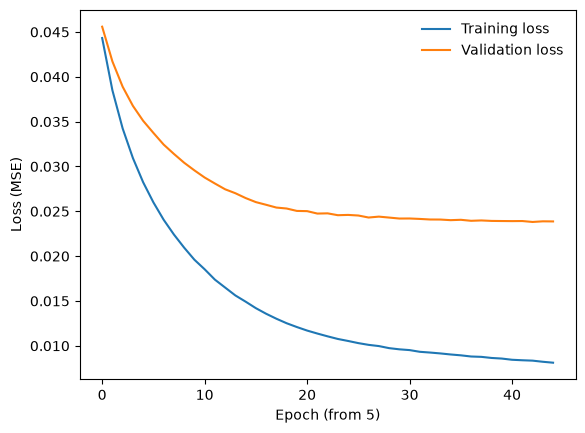

In [50]:
%matplotlib inline
import matplotlib.pyplot as plt

plt.plot(train_losses[5:], label='Training loss')    # on saute les 5 premières epochs (loss trop grande au début)
plt.plot(val_losses[5:], label='Validation loss')
plt.xlabel('Epoch (from 5)')
plt.ylabel('Loss (MSE)')
plt.legend(frameon=False)
plt.show()

In [54]:
test_df = data.iloc[1460:].drop(columns=['SalePrice'])          # on reprend le test depuis data
test_tensor = torch.from_numpy(test_df.values).float()          # nouveau nom : on n'écrase rien

with torch.no_grad():
    model.eval()
    output = model(test_tensor)

prix = torch.exp(output)  # revenir du log au prix en $
prix[:5]

tensor([[114561.2344],
        [155100.1094],
        [177372.6250],
        [186186.3594],
        [190388.5312]])

In [55]:
# compare the output from trained network,
# with the real output and calculate the score / accuracy
# DM 2.1
with torch.no_grad():
    model.eval()
    predictions = model(X_val)                    # prédictions en log(prix)
    score = torch.sqrt(criterion(predictions, y_val))  # pas de torch.log : déjà en log

print("Validation log RMSE:", score.item())
print("Predicted prices:", torch.exp(predictions[:5]).flatten())  # exp() pour revenir en $
print("Real prices:", torch.exp(y_val[:5]).flatten())

Validation log RMSE: 0.154496967792511
Predicted prices: tensor([141485.5625, 336865.7812,  95368.2344, 165997.9219, 319894.9375])
Real prices: tensor([154500.0000, 325000.0938, 114999.9609, 159000.0469, 315499.9688])


### We compare predicted prices with real prices using RMSE on log prices.
Our validation score is **0.15** (about 15% average error on the price). The predictions are close to the real prices

# Summary

## Goal
Predict house prices with a neural network.

## What we did
- Loaded the train and test data and merged them to prepare them the same way.
- Converted text columns into numbers with `get_dummies`.
- Filled missing values with the median.
- Scaled the features between 0 and 1 with `MinMaxScaler`.
- Split the train data into 1000 houses for training and 460 for validation.
- Built a network: 331 inputs → 128 → 64 → 1 output (ReLU).
- Trained it with MSE and Adam, and checked the RMSE on the validation set.
- Predicted the test prices and used `exp()` to get them back in $.

## Results
The score is about **0.155** (around 15% error), and the predictions are close to the real prices.

## What made the difference
- Predicting **log(price)** instead of the raw price.
- Using **ReLU** instead of sigmoid.
- Adding a **second hidden layer**.

## What we could still improve
- Use a smaller learning rate to make training more stable.
- Train for fewer epochs (around 50).
- Remove the `Id` column.